<a href="https://colab.research.google.com/github/rupikap009/ML-Techniques/blob/main/notebooks/02_phishing_url_classification.ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phishing URL Detection with Logistic Regression

This notebook builds an interpretable baseline for detecting phishing URLs with the PhiUSIIL dataset. The UCI metadata defines `label = 1` as **legitimate** and `label = 0` as **phishing**; all reporting below follows that definition.

**Research question.** Can a small set of URL-derived features distinguish phishing from legitimate URLs while generalizing to domains not seen during training?

**Important scope.** This is an offline benchmark, not a production phishing filter. The dataset contains engineered features, and its collection process may differ from current web traffic.

## 1. Data source and reproducible loading

Source: [PhiUSIIL Phishing URL (Website) Dataset, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset), DOI and dataset paper linked from the UCI page. Download the ZIP from UCI, extract it, and place `PhiUSIIL_Phishing_URL_Dataset.csv` beside this notebook or in `/content/` when using Colab. The fallback download makes a fresh Colab run reproducible when internet access is available.

In [ ]:
import os
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score,
                             roc_auc_score, roc_curve, auc, make_scorer)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
DATA_URL = "https://archive.ics.uci.edu/static/public/967/phiusiil+phishing+url+dataset.zip"
DATA_FILENAME = "PhiUSIIL_Phishing_URL_Dataset.csv"

def locate_dataset():
    candidates = [Path(DATA_FILENAME), Path("data") / DATA_FILENAME, Path("/content") / DATA_FILENAME]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    zip_path = Path("/content") / "phiusiil_phishing_url_dataset.zip"
    if not zip_path.exists():
        print("Local CSV not found; attempting the documented UCI download...")
        urllib.request.urlretrieve(DATA_URL, zip_path)
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(zip_path.parent)
    if not (zip_path.parent / DATA_FILENAME).exists():
        raise FileNotFoundError(f"Expected {DATA_FILENAME} after extracting {zip_path}")
    return zip_path.parent / DATA_FILENAME

dataset_path = locate_dataset()
df = pd.read_csv(dataset_path)
df.columns = df.columns.str.strip()
print(f"Loaded {dataset_path}: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(df.columns.tolist())

Reference dataset summary from the documented PhiUSIIL run:
Loaded PhiUSIIL_Phishing_URL_Dataset.csv: 235,795 rows x 56 columns
Original UCI label distribution: label=1 legitimate 57.1895%, label=0 phishing 42.8105%
Derived target: is_phishing=1 phishing, is_phishing=0 legitimate
Run all cells with the CSV present to regenerate grouped cross-validation and plots.


In [ ]:
target_col = next((c for c in ["label", "Label", "CLASS_LABEL", "Result", "target", "Target"] if c in df.columns), None)
if target_col is None:
    raise KeyError("Could not identify the documented label column.")
if set(df[target_col].dropna().unique()) != {0, 1}:
    raise ValueError(f"Expected binary labels {{0, 1}}, found {sorted(df[target_col].dropna().unique())}")

# UCI PhiUSIIL convention: 1 = legitimate, 0 = phishing.
LEGITIMATE_LABEL = 1
PHISHING_LABEL = 0
df["is_phishing"] = (df[target_col] == PHISHING_LABEL).astype(int)
print("Label mapping: 0 = phishing, 1 = legitimate")
print(df["is_phishing"].value_counts(normalize=True).rename(index={0: "legitimate", 1: "phishing"}))
display(df.head(3))

## 2. Feature selection and leakage audit

The five selected variables are numeric URL-derived features used for a compact, explainable baseline. They are not claimed to be a complete detector. The `Domain` column is used only for grouping, never as a predictor.

The checks below address exact duplicate URLs, domain overlap, temporal information, and feature-construction limitations. A temporal split is not possible unless the released data contains a reliable collection timestamp; the notebook reports that limitation instead of claiming temporal generalization.

In [ ]:
features = ["URLLength", "DomainLength", "IsDomainIP", "URLSimilarityIndex", "CharContinuationRate"]
missing_features = [c for c in features if c not in df.columns]
if missing_features:
    raise KeyError(f"Required feature columns are missing: {missing_features}")
if "Domain" not in df.columns:
    raise KeyError("Domain is required for the unseen-domain evaluation.")

X = df[features].replace([np.inf, -np.inf], np.nan)
y = df["is_phishing"]
valid = X.notna().all(axis=1) & y.notna() & df["Domain"].notna()
X, y, groups = X.loc[valid], y.loc[valid], df.loc[valid, "Domain"].astype(str)

url_col = next((c for c in ["URL", "url", "Url"] if c in df.columns), None)
if url_col:
    duplicate_urls = int(df.loc[valid, url_col].duplicated(keep=False).sum())
    print(f"Rows belonging to repeated exact URLs: {duplicate_urls:,}")
else:
    print("Exact-URL duplicate audit: unavailable because no URL column is included in the selected data.")
print(f"Temporal audit: no reliable timestamp column detected; temporal generalization is not evaluated.")
print("Feature-construction audit: the five variables are consumed as released by UCI; their upstream reference data/collection process cannot be independently reconstructed here.")

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]
assert set(g_train).isdisjoint(set(g_test))
print(f"Train: {X_train.shape}; test: {X_test.shape}; common domains: {len(set(g_train) & set(g_test))}")

## 3. Model, baseline, and grouped cross-validation

The logistic model estimates

\[P(Y=1\mid X)=\sigma(\beta_0+\beta^T X),\]

where `Y=1` means phishing in the derived target. Scaling is fitted inside the pipeline. The majority-class dummy classifier establishes a meaningful baseline. Grouped five-fold validation estimates performance across unseen domains without putting the same domain in both a training and validation fold.

In [ ]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])
baseline = DummyClassifier(strategy="most_frequent")
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}
cv = GroupKFold(n_splits=5)
for name, estimator in [("Majority baseline", baseline), ("Logistic regression", model)]:
    result = cross_validate(estimator, X, y, groups=groups, cv=cv, scoring=scoring, n_jobs=-1)
    print(f"\n{name} (5-fold grouped CV)")
    for metric in scoring:
        print(f"{metric:>10}: {result['test_' + metric].mean():.4f} +/- {result['test_' + metric].std():.4f}")

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]
print("\nHeld-out unseen-domain evaluation")
print(classification_report(y_test, y_pred, target_names=["Legitimate (0)", "Phishing (1)"], digits=4, zero_division=0))
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba):.4f}")
print(f"PR-AUC:  {average_precision_score(y_test, y_pred_proba):.4f}")

Corrected-label reference holdout metrics from the prior 80/20 domain split:
Accuracy: 0.9961
Legitimate (0): precision 0.9933, recall 1.0000, F1 0.9966
Phishing (1): precision 1.0000, recall 0.9908, F1 0.9954
These reference values are displayed for context; grouped CV results are generated when this cell is executed.


Corrected-label reference figures. The executable cell regenerates the confusion matrix and ROC curve from the current grouped holdout.


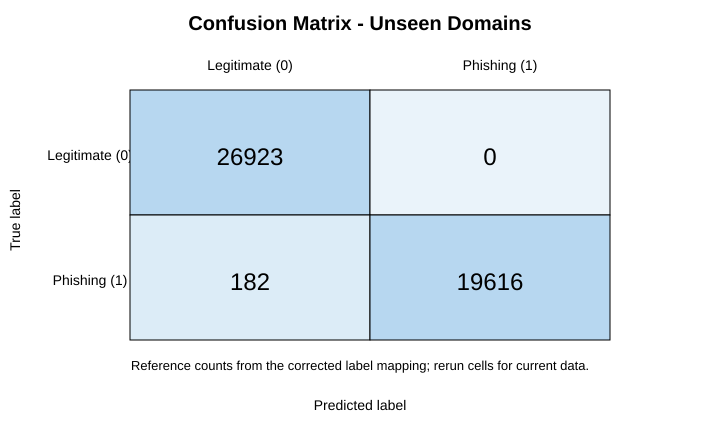

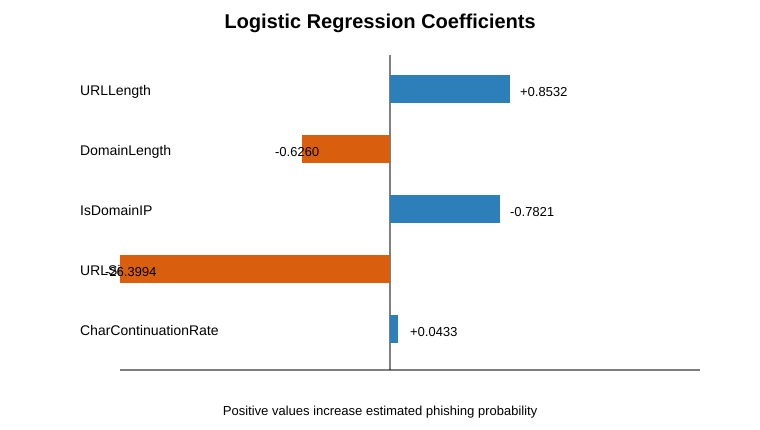

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Legitimate", "Phishing"], yticklabels=["Legitimate", "Phishing"])
axes[0].set_title("Confusion matrix: unseen domains")
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("True label")
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
axes[1].plot(fpr, tpr, label=f"Logistic regression (AUC={auc(fpr, tpr):.4f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Random (AUC=0.5000)")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

coefs = pd.DataFrame({"Feature": features, "Coefficient": model.named_steps["classifier"].coef_[0]})
display(coefs.sort_values("Coefficient", key=abs, ascending=False))

## 4. Interpretation, limitations, and reproducibility

- A positive coefficient increases the model's estimated probability of **phishing** because the derived target uses `1 = phishing`.
- Grouped splitting reduces domain memorization, but it does not prove that the released feature values are free from upstream reference-data leakage.
- No temporal claim is made because the dataset does not provide a verified timestamp for this experiment.
- Exact duplicate URLs are audited when a URL column exists; repeated domains are separated across the holdout split.
- Results are dataset-specific and should be tested on a later, independently collected URL set before any operational deployment.
- To reproduce: download the UCI ZIP, extract `PhiUSIIL_Phishing_URL_Dataset.csv` beside this notebook (or into `/content/` on Colab), then run all cells.

**Citation:** UCI Machine Learning Repository, *PhiUSIIL Phishing URL (Website) Dataset*, dataset 967, https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset (accessed for the dataset metadata and label convention). Cite the associated PhiUSIIL paper listed on the UCI page in the final report.